In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

from scipy.cluster.hierarchy import linkage, dendrogram

A.3 – Create the Working Dataset

In [3]:
X, _ = make_blobs(
    n_samples=180,
    centers=3,
    cluster_std=1.15,
    random_state=42
)

# Give the two features noticeably different scales
X[:, 0] = X[:, 0] * 10 + 50
X[:, 1] = X[:, 1] * 1000 + 50000

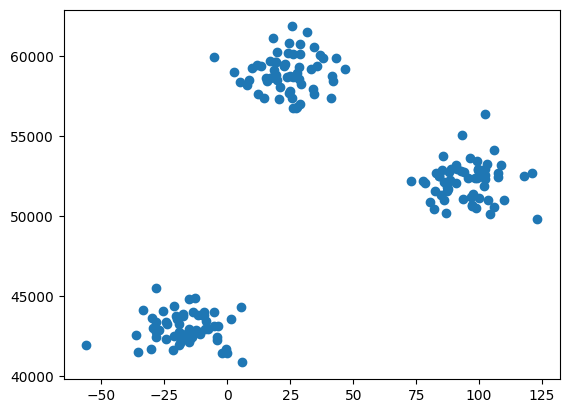

In [4]:
#scatterplot vizualization
plt.scatter(X[:, 0], X[:, 1])
plt.show()


In [5]:
#standardize oth features using standardscaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

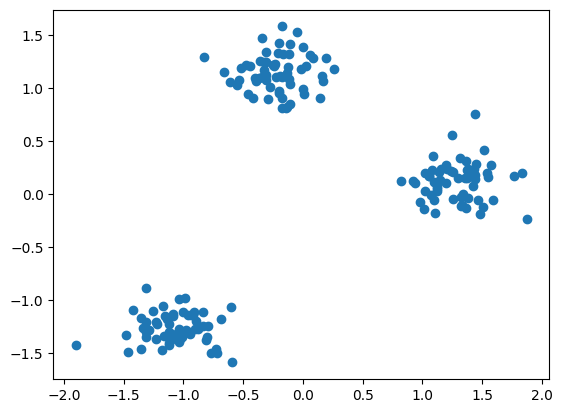

In [6]:
#Createing second scatterplot using the scaled feature
plt.scatter(X_scaled[:, 0], X_scaled[:, 1])
plt.show()

B.2 – Step 1: Initialize Centroids


Task 5 – Write the Initialization Function


In [7]:
def initialize_centroids(X, K, seed=42):
    rng = np.random.default_rng(seed)

    indices = rng.choice(
        X.shape[0],
        size=K,
        replace=False
    )

    centroids = X[indices].copy()

    return centroids

In [8]:
initial_centroids = initialize_centroids(
    X_scaled,
    K=3,
    seed=42
)

print("Initial centroids:")
print(initial_centroids)

Initial centroids:
[[-0.47257087  1.21619271]
 [-1.12007651 -1.22665482]
 [ 0.02850096  1.20804729]]


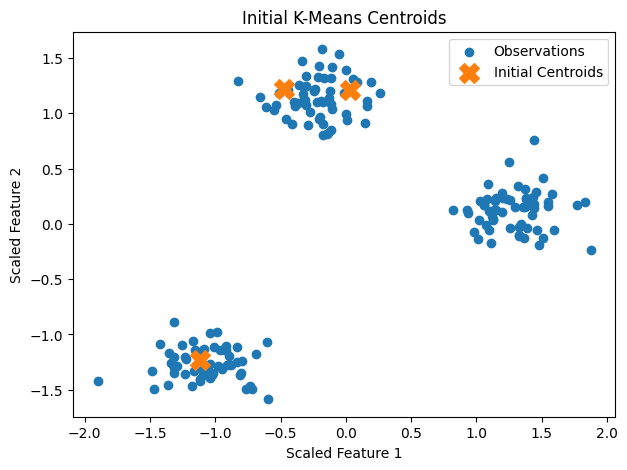

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    label="Observations"
)

plt.scatter(
    initial_centroids[:, 0],
    initial_centroids[:, 1],
    marker="X",
    s=200,
    label="Initial Centroids"
)

plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.title("Initial K-Means Centroids")

plt.legend()
plt.show()

Task 6 – Euclidean Distance and Cluster Assignment


In [10]:
def assign_clusters(X, centroids):

    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )

    labels = np.argmin(distances, axis=1)

    return labels

In [11]:
labels = assign_clusters(
    X_scaled,
    initial_centroids
)

print(labels)

[1 2 1 1 1 2 2 1 1 2 2 0 2 2 2 1 2 2 0 2 1 2 2 1 0 2 2 2 1 2 0 1 1 0 1 0 2
 2 2 1 2 1 1 1 1 2 0 2 1 0 1 2 2 2 2 1 0 2 2 2 2 1 1 1 2 1 1 0 2 1 2 2 2 2
 2 2 1 2 2 1 0 2 2 2 2 1 0 2 1 1 2 2 2 0 1 1 2 2 2 1 0 0 0 1 2 2 2 1 2 1 2
 2 2 2 2 0 2 0 1 2 2 2 2 1 2 2 2 0 2 2 2 0 1 2 2 1 0 2 2 2 0 2 1 2 2 1 2 1
 2 2 2 0 1 0 1 2 1 2 1 1 2 0 1 1 0 1 1 2 2 1 2 2 1 1 1 0 2 1 2 1]


In [12]:
cluster_counts = np.bincount(
    labels,
    minlength=3
)

print("Cluster counts:")
print(cluster_counts)

Cluster counts:
[27 60 93]


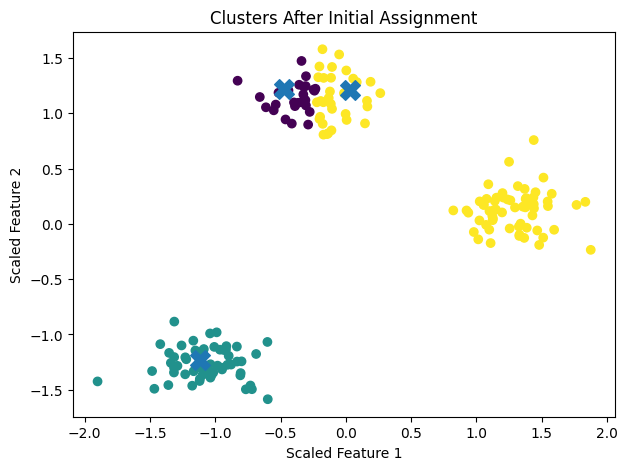

In [13]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels
)

plt.scatter(
    initial_centroids[:, 0],
    initial_centroids[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.title("Clusters After Initial Assignment")

plt.show()

Task 7 — Update Centroids

In [14]:
def update_centroids(X, labels, K):

    new_centroids = []

    for k in range(K):

        cluster_points = X[labels == k]

        centroid = cluster_points.mean(axis=0)

        new_centroids.append(centroid)

    return np.array(new_centroids)

In [15]:
new_centroids = update_centroids(
    X_scaled,
    labels,
    K=3
)

print("Old centroids:")
print(initial_centroids)

print("\nNew centroids:")
print(new_centroids)

Old centroids:
[[-0.47257087  1.21619271]
 [-1.12007651 -1.22665482]
 [ 0.02850096  1.20804729]]

New centroids:
[[-0.40135987  1.14312934]
 [-1.07094623 -1.26443534]
 [ 0.80745688  0.48388847]]


Task 8 – Build the Full K-Means Training Loop


In [16]:
def kmeans_from_scratch(
    X,
    K,
    seed=42,
    max_iters=100,
    tol=1e-4
):

    centroids = initialize_centroids(
        X,
        K,
        seed
    )

    for iteration in range(max_iters):

        # Step 1: assign observations
        labels = assign_clusters(
            X,
            centroids
        )

        # Step 2: calculate new centroids
        new_centroids = update_centroids(
            X,
            labels,
            K
        )

        # Step 3: check convergence
        if np.allclose(
            centroids,
            new_centroids,
            atol=tol
        ):
            centroids = new_centroids

            labels = assign_clusters(
                X,
                centroids
            )

            return labels, centroids, iteration + 1

        centroids = new_centroids

    labels = assign_clusters(
        X,
        centroids
    )

    return labels, centroids, max_iters

In [17]:
labels_final, centroids_final, iterations = kmeans_from_scratch(
    X_scaled,
    K=3,
    seed=42
)

print("Iterations:", iterations)

print("\nFinal centroids:")
print(centroids_final)

print("\nCluster counts:")
print(np.bincount(labels_final))

Iterations: 3

Final centroids:
[[-0.21623158  1.14155361]
 [-1.07094623 -1.26443534]
 [ 1.28717781  0.12288172]]

Cluster counts:
[60 60 60]


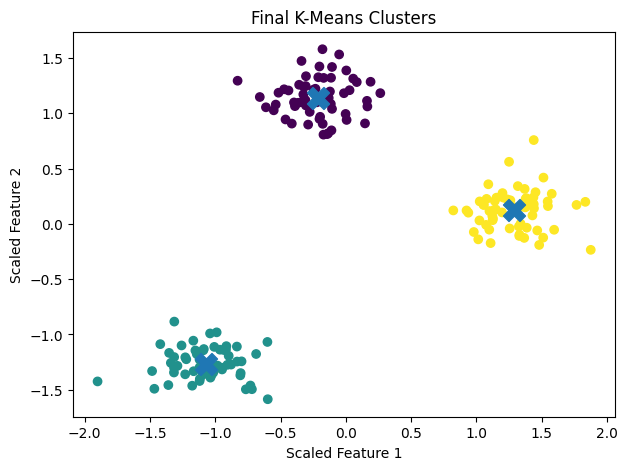

In [18]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_final
)

plt.scatter(
    centroids_final[:, 0],
    centroids_final[:, 1],
    marker="X",
    s=250
)

plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.title("Final K-Means Clusters")

plt.show()

In [19]:
labels_seed7, centroids_seed7, iterations_seed7 = kmeans_from_scratch(
    X_scaled,
    K=3,
    seed=7
)

print("Iterations:", iterations_seed7)

print("Centroids:")
print(centroids_seed7)

print("Cluster counts:")
print(np.bincount(labels_seed7))

Iterations: 2
Centroids:
[[ 1.28717781  0.12288172]
 [-0.21623158  1.14155361]
 [-1.07094623 -1.26443534]]
Cluster counts:
[60 60 60]


Task 9 — WCSS and Elbow Method

In [20]:
def calculate_wcss(X, labels, centroids):

    wcss = 0

    for k in range(len(centroids)):

        cluster_points = X[labels == k]

        squared_distances = (
            cluster_points - centroids[k]
        ) ** 2

        wcss += np.sum(squared_distances)

    return wcss

In [21]:
wcss_k3 = calculate_wcss(
    X_scaled,
    labels_final,
    centroids_final
)

print("WCSS for K = 3:", wcss_k3)

WCSS for K = 3: 13.947004341513955


In [22]:
K_values = range(1, 9)

wcss_values = []

for K in K_values:

    labels_k, centroids_k, iterations_k = kmeans_from_scratch(
        X_scaled,
        K=K,
        seed=42
    )

    wcss = calculate_wcss(
        X_scaled,
        labels_k,
        centroids_k
    )

    wcss_values.append(wcss)

    print(
        "K =", K,
        "WCSS =", round(wcss, 3)
    )

K = 1 WCSS = 360.0
K = 2 WCSS = 112.885
K = 3 WCSS = 13.947
K = 4 WCSS = 12.259
K = 5 WCSS = 10.331
K = 6 WCSS = 9.295
K = 7 WCSS = 9.176
K = 8 WCSS = 8.288


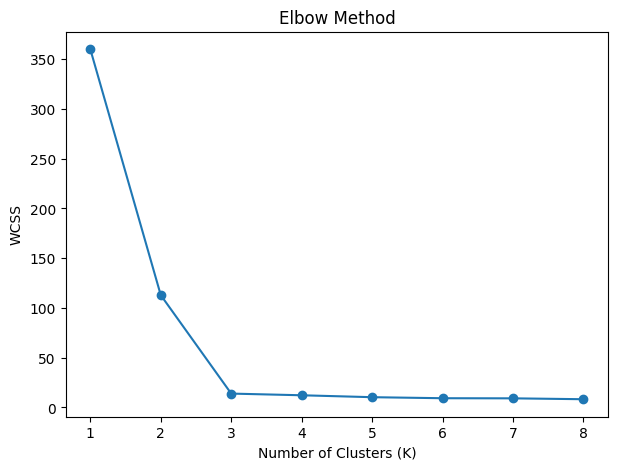

In [23]:
plt.figure(figsize=(7, 5))

plt.plot(
    list(K_values),
    wcss_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(list(K_values))

plt.show()

Task 10 — Verify with Scikit-learn KMeans

In [24]:
sklearn_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

sklearn_labels = sklearn_kmeans.fit_predict(
    X_scaled
)

print("Scikit-learn centroids:")
print(sklearn_kmeans.cluster_centers_)

print("\nScikit-learn inertia:")
print(sklearn_kmeans.inertia_)

Scikit-learn centroids:
[[-0.21623158  1.14155361]
 [-1.07094623 -1.26443534]
 [ 1.28717781  0.12288172]]

Scikit-learn inertia:
13.94700434151395


Task 11 — Build Dendrograms

Single linkage

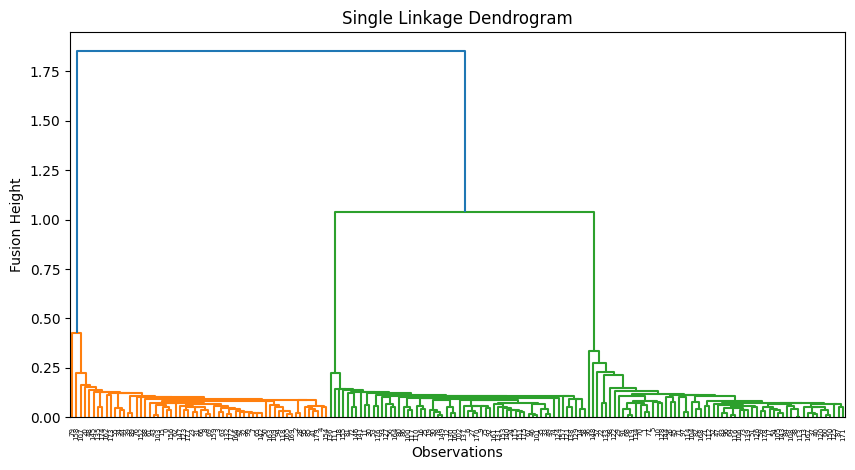

In [25]:
Z_single = linkage(
    X_scaled,
    method="single"
)

plt.figure(figsize=(10, 5))

dendrogram(Z_single)

plt.title("Single Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Fusion Height")

plt.show()

Complete linkage

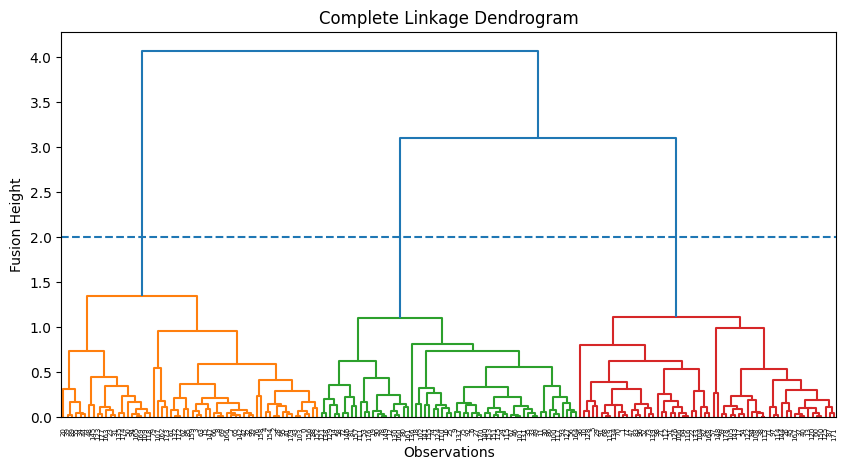

In [26]:
Z_complete = linkage(
    X_scaled,
    method="complete"
)

plt.figure(figsize=(10, 5))

dendrogram(Z_complete)

plt.axhline(
    y=2.0,
    linestyle="--"
)

plt.title("Complete Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Fusion Height")

plt.show()

Average linkage

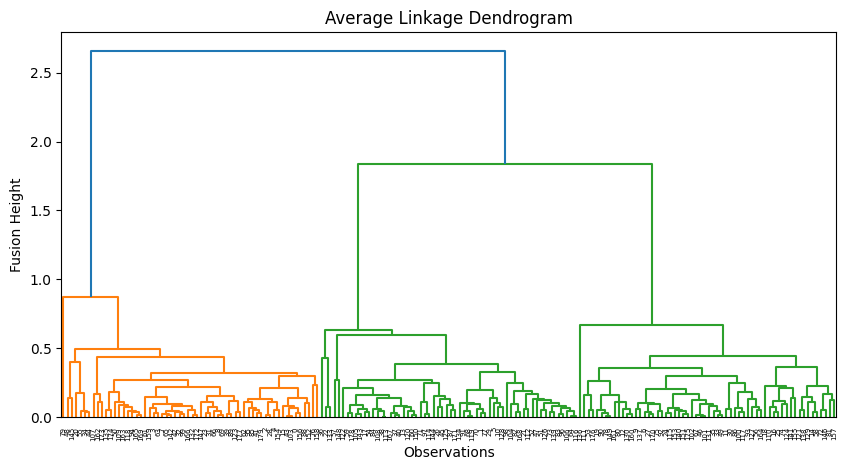

In [27]:
Z_average = linkage(
    X_scaled,
    method="average"
)

plt.figure(figsize=(10, 5))

dendrogram(Z_average)

plt.title("Average Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Fusion Height")

plt.show()

Task 12 — Agglomerative Clustering

Complete linkage

In [28]:
agg_complete = AgglomerativeClustering(
    n_clusters=3,
    linkage="complete"
)

labels_complete = agg_complete.fit_predict(
    X_scaled
)

print(
    np.bincount(labels_complete)
)

[60 60 60]


Plot:

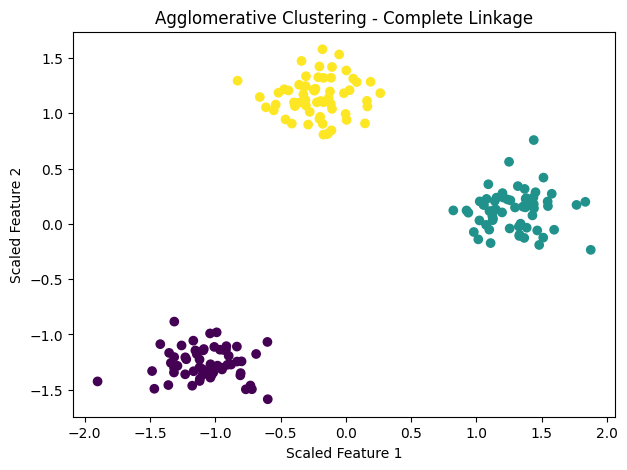

In [29]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_complete
)

plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.title("Agglomerative Clustering - Complete Linkage")

plt.show()

Average linkage

In [30]:
agg_average = AgglomerativeClustering(
    n_clusters=3,
    linkage="average"
)

labels_average = agg_average.fit_predict(
    X_scaled
)

print(
    np.bincount(labels_average)
)

[60 60 60]


Plot:

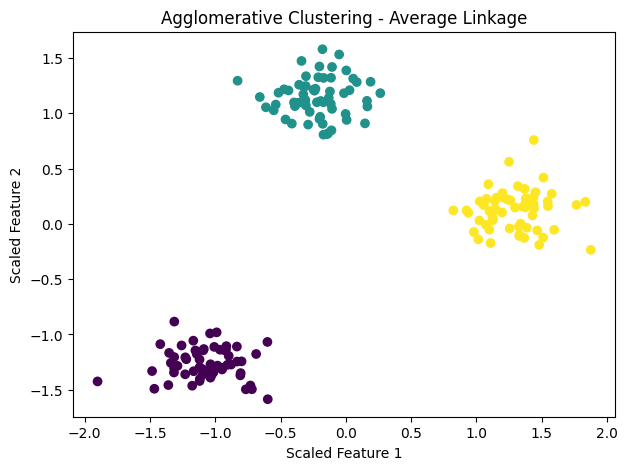

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_average
)

plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.title("Agglomerative Clustering - Average Linkage")

plt.show()

Part D — DBSCAN

Task 13 — Arbitrary-Shaped Clusters and Noise

In [32]:
X_moons, _ = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

X_moons = StandardScaler().fit_transform(
    X_moons
)

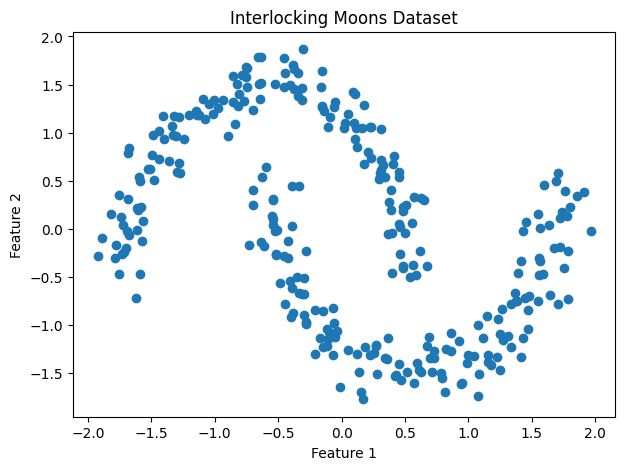

In [33]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1]
)

plt.title("Interlocking Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [34]:
def run_dbscan(X, eps_value, min_samples_value=5):

    model = DBSCAN(
        eps=eps_value,
        min_samples=min_samples_value
    )

    labels = model.fit_predict(X)

    unique_labels = set(labels)

    n_clusters = len(unique_labels) - (
        1 if -1 in unique_labels else 0
    )

    n_noise = np.sum(labels == -1)

    return labels, n_clusters, n_noise

In [35]:
labels_015, clusters_015, noise_015 = run_dbscan(
    X_moons,
    0.15,
    5
)

print("Clusters:", clusters_015)
print("Noise points:", noise_015)

Clusters: 18
Noise points: 53


In [36]:
labels_025, clusters_025, noise_025 = run_dbscan(
    X_moons,
    0.25,
    5
)

print("Clusters:", clusters_025)
print("Noise points:", noise_025)

Clusters: 2
Noise points: 2


In [37]:
labels_040, clusters_040, noise_040 = run_dbscan(
    X_moons,
    0.40,
    5
)

print("Clusters:", clusters_040)
print("Noise points:", noise_040)

Clusters: 2
Noise points: 0


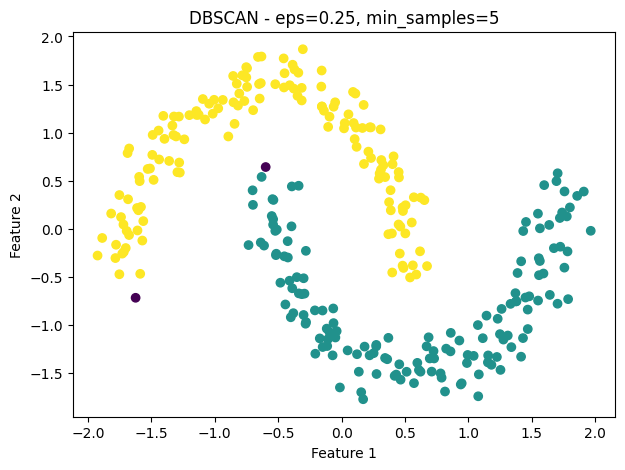

In [38]:
best_dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

best_dbscan_labels = best_dbscan.fit_predict(
    X_moons
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=best_dbscan_labels
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN - eps=0.25, min_samples=5")

plt.show()

Task 14 — Compare DBSCAN with K-Means

In [39]:
moon_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

moon_kmeans_labels = moon_kmeans.fit_predict(
    X_moons
)

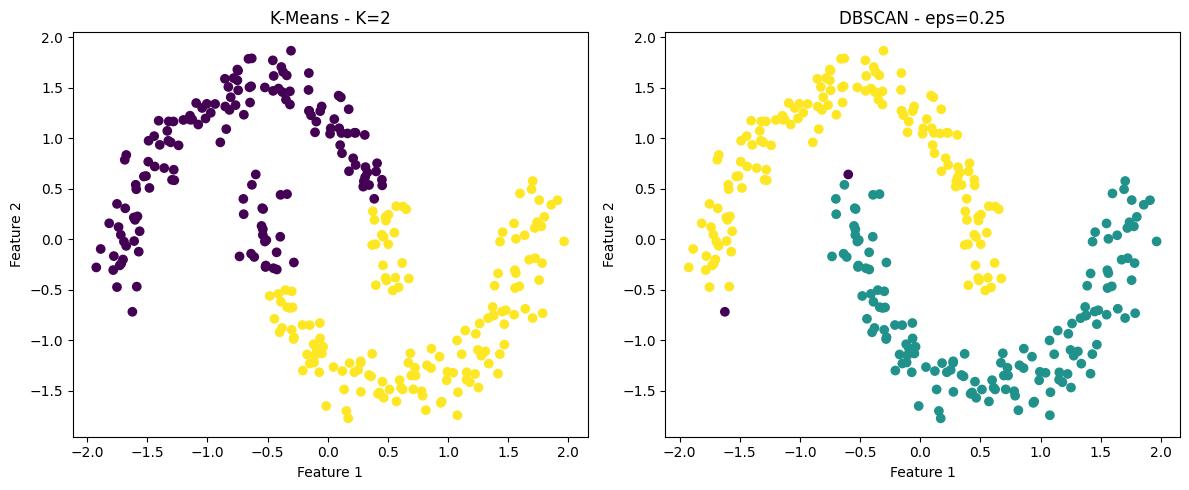

In [40]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=moon_kmeans_labels
)

plt.title("K-Means - K=2")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")


plt.subplot(1, 2, 2)

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=best_dbscan_labels
)

plt.title("DBSCAN - eps=0.25")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()